# FIG1 — Distribution of Gleason Grade Group, field strength, and scanner by center

Inputs: `labels_clean_*.csv` and `labels_scanner_uptodate.csv`. The preparation cell assigns centers using the same cohort boundaries as the source notebook. The saved plot output from the source notebook is preserved.


In [ ]:
from pathlib import Path
import pandas as pd

# Match the feature_tables_FINAL_2D folder selected in the source notebook.
base = Path("feature_tables_FINAL_2D") / "T2_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original__ADC_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original_BIN_16"
labels_path = next(base.glob("labels_clean_*.csv"))
labels_all = pd.read_csv(labels_path)
labels_all["scanner"] = pd.read_csv("labels_scanner_uptodate.csv")["scanner"]

# Restore center labels from the row ordering used by the source notebook.
IDX_US = 876
IDX_PICAI = 425
IDX_NOV = 77
labels_us = labels_all.iloc[:IDX_US].copy()
labels_prostatex = labels_all.iloc[IDX_US:IDX_US + IDX_PICAI].reset_index(drop=True)
labels_nov = labels_all.iloc[IDX_US + IDX_PICAI:IDX_US + IDX_PICAI + IDX_NOV].reset_index(drop=True)
labels_tor = labels_all.iloc[IDX_US + IDX_PICAI + IDX_NOV:].reset_index(drop=True)

labels_us["center"] = "US-MRI"
labels_prostatex["center"] = "PI-CAI"
labels_nov["center"] = "NOVARA"
labels_tor["center"] = "TORINO"
labels_all = pd.concat(
    [labels_us, labels_prostatex, labels_nov, labels_tor],
    ignore_index=True,
)


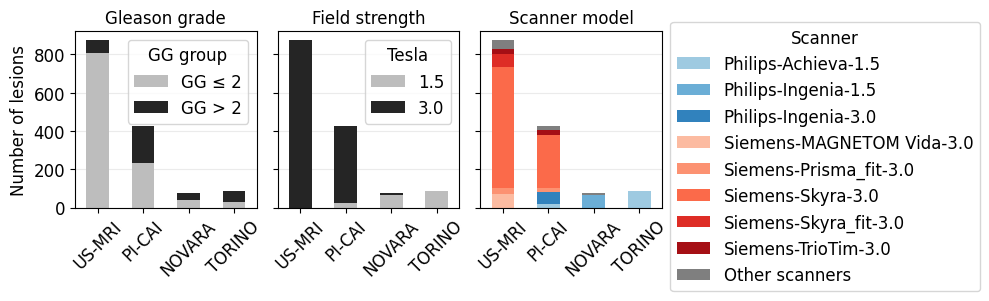

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def clean_scanner_name(s):
    s = str(s)

    s = s.replace("Philips Medical Systems", "Philips")
    s = s.replace("Siemens HealthCare GmbH", "Siemens")
    s = s.replace("SIEMENS", "Siemens")

    remove_tags = [
        "-PCNN", "-RUMC", "-ZGT",
        "-syngo MR D11", "-syngo MR D13", "-syngo MR E11",
        "-syngo MR B17", "-syngo MR XA10",
    ]

    for tag in remove_tags:
        s = s.replace(tag, "")

    return s


def scanner_color_map(scanner_names):
    """
    Vendor-aware qualitative colors:
    Philips = blue family
    Siemens = red/orange family
    Other = gray
    """
    philips_colors = [
        "#9ecae1", "#6baed6", "#3182bd", "#08519c"
    ]

    siemens_colors = [
        "#fcbba1", "#fc9272", "#fb6a4a", "#de2d26",
        "#a50f15", "#67000d"
    ]

    other_color = "#7f7f7f"

    colors = {}
    p_i = 0
    s_i = 0

    for name in scanner_names:
        if name == "Other scanners":
            colors[name] = other_color

        elif "Philips" in name:
            colors[name] = philips_colors[p_i % len(philips_colors)]
            p_i += 1

        elif "Siemens" in name:
            colors[name] = siemens_colors[s_i % len(siemens_colors)]
            s_i += 1

        else:
            colors[name] = other_color

    return colors


CENTER_ORDER = ["US-MRI", "PI-CAI", "NOVARA", "TORINO"]
MIN_SCANNER_CASES = 50

for i, df in enumerate([labels_all]):  # add labels_all_pred if needed

    df_plot = df.copy()

    # =====================================================
    # Center order
    # =====================================================
    existing_centers = [c for c in CENTER_ORDER if c in df_plot["center"].unique()]
    remaining_centers = [c for c in df_plot["center"].unique() if c not in existing_centers]
    center_order = existing_centers + remaining_centers

    # =====================================================
    # 1) GG binary
    # =====================================================
    df_plot["GG_bin"] = np.where(df_plot["GG"] <= 2, "GG ≤ 2", "GG > 2")

    tab_gg_center = pd.crosstab(df_plot["center"], df_plot["GG_bin"])
    tab_gg_center = tab_gg_center.reindex(index=center_order, fill_value=0)

    gg_order = ["GG ≤ 2", "GG > 2"]
    tab_gg_center = tab_gg_center.reindex(columns=gg_order, fill_value=0)

    colors_gg = {
        "GG ≤ 2": "#bdbdbd",
        "GG > 2": "#252525",
    }

    # =====================================================
    # 2) Tesla
    # =====================================================
    if "tesla" in df_plot.columns:
        tesla_series = df_plot["tesla"].astype(str)
    elif "Tesla" in df_plot.columns:
        tesla_series = df_plot["Tesla"].astype(str)
    else:
        tesla_series = (
            df_plot["scanner"]
            .astype(str)
            .str.extract(r"(1\.5|3\.0)", expand=False)
        )

    tesla_series = (
        tesla_series
        .replace({"3": "3.0", "1.5T": "1.5", "3.0T": "3.0"})
        .fillna("Unknown")
    )

    tab_tesla_center = pd.crosstab(df_plot["center"], tesla_series)
    tab_tesla_center = tab_tesla_center.reindex(index=center_order, fill_value=0)

    tesla_order = [c for c in ["1.5", "3.0", "Unknown"] if c in tab_tesla_center.columns]
    tab_tesla_center = tab_tesla_center.reindex(columns=tesla_order, fill_value=0)

    colors_tesla = {
        "1.5": "#bdbdbd",
        "3.0": "#252525",
        "Unknown": "#f0f0f0",
    }

    # =====================================================
    # 3) Scanner grouped
    # =====================================================
    df_plot["scanner_clean"] = df_plot["scanner"].apply(clean_scanner_name)

    scanner_counts = df_plot["scanner_clean"].value_counts()
    major_scanners = scanner_counts[scanner_counts >= MIN_SCANNER_CASES].index

    df_plot["scanner_grouped"] = np.where(
        df_plot["scanner_clean"].isin(major_scanners),
        df_plot["scanner_clean"],
        "Other scanners"
    )

    tab_scanner_center = pd.crosstab(df_plot["center"], df_plot["scanner_grouped"])
    tab_scanner_center = tab_scanner_center.reindex(index=center_order, fill_value=0)

    scanner_cols = [c for c in tab_scanner_center.columns if c != "Other scanners"]
    scanner_cols = sorted(scanner_cols)

    if "Other scanners" in tab_scanner_center.columns:
        scanner_cols += ["Other scanners"]

    tab_scanner_center = tab_scanner_center.reindex(columns=scanner_cols, fill_value=0)

    colors_scanner_dict = scanner_color_map(scanner_cols)
    colors_scanner = [colors_scanner_dict[c] for c in scanner_cols]

    # =====================================================
    # Plot
    # =====================================================
    fig, ax = plt.subplots(
        1, 3,
        figsize=(10, 3),
        sharey=True
    )

    tab_gg_center.plot(
        kind="bar",
        stacked=True,
        ax=ax[0],
        color=[colors_gg[c] for c in tab_gg_center.columns],
        edgecolor="none"
    )

    tab_tesla_center.plot(
        kind="bar",
        stacked=True,
        ax=ax[1],
        color=[colors_tesla[c] for c in tab_tesla_center.columns],
        edgecolor="none"
    )

    tab_scanner_center.plot(
        kind="bar",
        stacked=True,
        ax=ax[2],
        color=colors_scanner,
        edgecolor="none"
    )

    panel_titles = [
        "Gleason grade",
        "Field strength",
        "Scanner model"
    ]

    for a, title in zip(ax, panel_titles):
        a.set_title(title, fontsize=12)
        a.set_xlabel("")
        a.tick_params(axis="x", rotation=45, labelsize=12)
        a.tick_params(axis="y", labelsize=12)
        a.grid(axis="y", alpha=0.25)
        a.set_axisbelow(True)

    ax[0].set_ylabel("Number of lesions", fontsize=12)
    ax[1].set_ylabel("")
    ax[2].set_ylabel("")

    ax[0].legend(title="GG group", fontsize=12, title_fontsize=12, frameon=True)
    ax[1].legend(title="Tesla", fontsize=12, title_fontsize=12, frameon=True)

    ax[2].legend(
        title="Scanner",
        bbox_to_anchor=(1, 1.1),
        loc="upper left",
        fontsize=12,
        title_fontsize=12,
        frameon=True
    )

    ax[0].set_ylabel("Number of lesions", fontsize=12)
    plt.tight_layout()

    TYPE = "gt" if i == 0 else "pred"
    plt.savefig(
        f"figures_report/data_GG_tesla_scanner_{TYPE}.pdf",
        bbox_inches="tight"
    )
    plt.show()